Alphabet (-2, -1, 1, 2): max OAM orthogonality error = 4.46e-10; ANG error = 2.23e-10
Alphabet (-3, -1, 1, 3): max OAM orthogonality error = 3.64e-10; ANG error = 6.66e-16
Alphabet (-4, -2, 2, 4): max OAM orthogonality error = 3.22e-08; ANG error = 1.59e-08
Alphabet (-6, -3, 3, 6): max OAM orthogonality error = 3.18e-07; ANG error = 1.59e-07

Pilot selection table:
 D_over_r0 selected_alphabet
       0.0    (-2, -1, 1, 2)
       0.3    (-3, -1, 1, 3)
       0.6    (-3, -1, 1, 3)
       0.9    (-3, -1, 1, 3)
       1.2    (-6, -3, 3, 6)
       1.5    (-3, -1, 1, 3)
       1.8    (-3, -1, 1, 3)

Headline results (means):
 D_over_r0       strategy  qder_mean_mean  efficiency_mean_mean  secret_fraction_mean  secure_yield_proxy_mean
       0.0  Fixed compact          0.0000                1.0000                2.0000                   1.0000
       0.0 Pilot-selected          0.0000                1.0000                2.0000                   1.0000
       0.3  Fixed compact          0.010

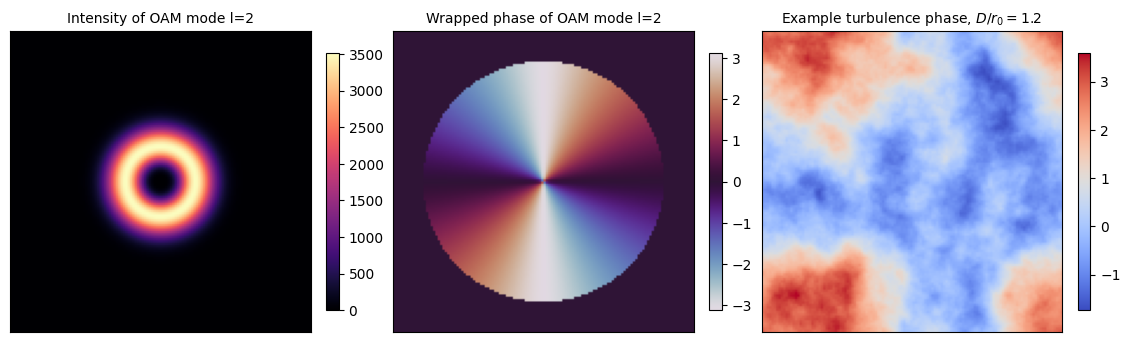

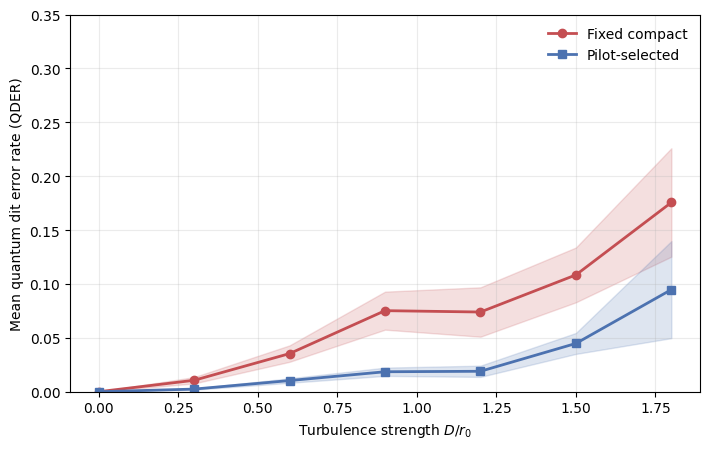

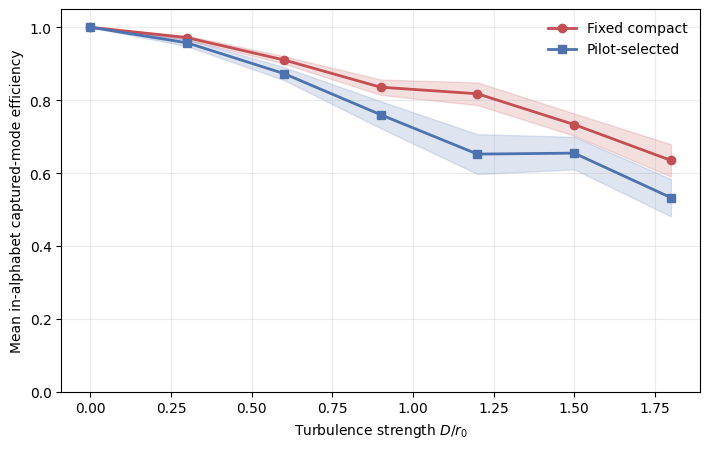

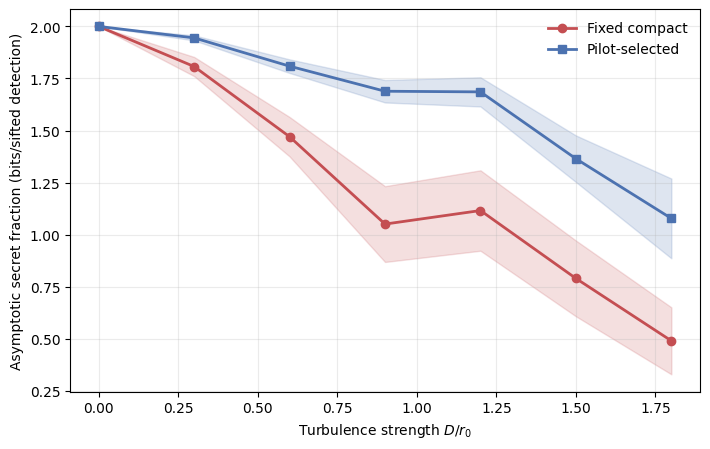

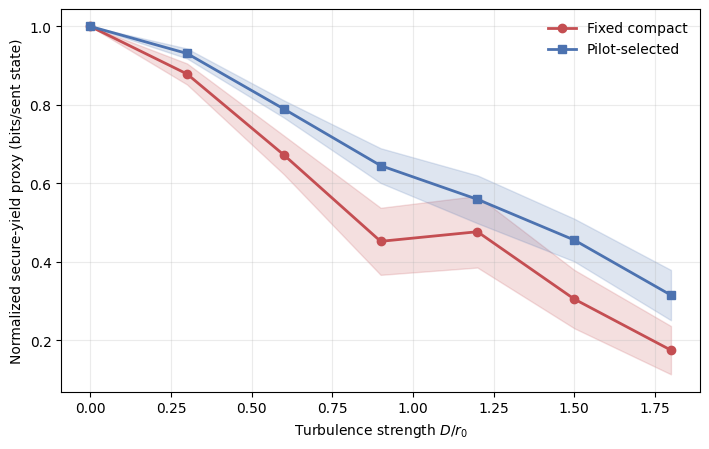

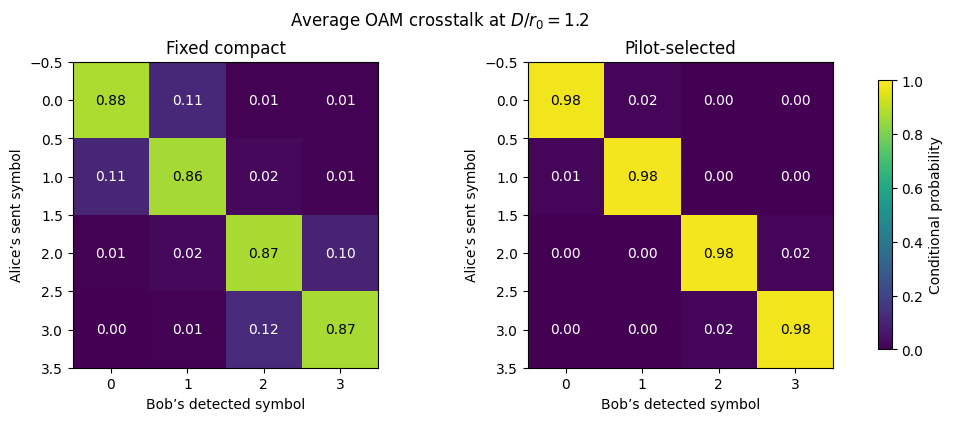


All checks passed. Results were saved to: /content/oam_qkd_outputs
ZIP file created: /content/oam_qkd_complete_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
"""
OAM-BASED HIGH-DIMENSIONAL QKD UNDER SIMULATED ATMOSPHERIC TURBULENCE

This single script is written for Google Colab and for a beginner.
It creates its own synthetic dataset; no external dataset is needed.

Scientific scope:
* Laguerre-Gaussian p=0 spatial modes represent OAM states.
* A thin Kolmogorov phase screen represents weak-to-moderate turbulence.
* A four-dimensional prepare-and-measure protocol uses an OAM basis and
its discrete-Fourier-transform angular (ANG) basis.
* A pilot-aided alphabet-selection strategy is compared with a fixed,
compact OAM alphabet on independent test screens.

Important limitation:
The key-rate calculation is an asymptotic, normalized model. It is not a
claim about absolute secret bits per second from a complete field system.
Detector dark counts, decoy states, finite-key corrections, and an
eavesdropper implementation are outside this eight-week project.
"""

# =========================== CELL 1: IMPORTS ===========================
# NumPy handles arrays and complex optical fields.
# Pandas stores the results as tables/CSV files.
# Matplotlib draws figures.
# pathlib and shutil create the output folder and ZIP file.
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ======================= CELL 2: USER SETTINGS =========================
# Keeping all important settings together makes the experiment easy to audit.

SEED = 20260812 # makes every rerun reproducible
DIMENSION = 4 # four symbols (a ququart protocol)
GRID_POINTS = 96 # pixels along x and y; increase to 128 for a check
GRID_SIDE_M = 0.060 # simulated square window: 6.0 cm
APERTURE_DIAMETER_M = 0.048 # receiver aperture diameter: 4.8 cm
BEAM_WAIST_M = 0.007 # OAM beam waist: 7 mm
OUTER_SCALE_M = 10.0 # von Karman outer scale used in the spectrum

# D/r0 is the dimensionless turbulence strength.
# 0 means no turbulence; larger values mean stronger phase distortion.
STRENGTHS = np.array([0.0, 0.3, 0.6, 0.9, 1.2, 1.5, 1.8])

# Number of random screens used for selection and final evaluation.
# Pilot screens choose an alphabet. Test screens independently evaluate it.
N_PILOT = 10
N_TEST = 30
N_HEATMAP = 40

# Four possible four-symbol OAM alphabets. The first is the fixed baseline.
# Wider separation between l values is expected to reduce nearest-mode mixing.
CANDIDATE_ALPHABETS = [
(-2, -1, 1, 2),
(-3, -1, 1, 3),
(-4, -2, 2, 4),
(-6, -3, 3, 6),
]
BASELINE_ALPHABET = CANDIDATE_ALPHABETS[0]

OUTPUT_DIR = Path("oam_qkd_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


# ===================== CELL 3: SPATIAL COORDINATES =====================
# The grid represents the receiver plane. Every optical field is sampled here.
dx = GRID_SIDE_M / GRID_POINTS
axis = (np.arange(GRID_POINTS) - GRID_POINTS / 2 + 0.5) * dx
X, Y = np.meshgrid(axis, axis, indexing="xy")
R = np.sqrt(X**2 + Y**2)
THETA = np.arctan2(Y, X)
APERTURE = R <= APERTURE_DIAMETER_M / 2


def inner_product(field_a, field_b):
  """Numerical version of integral conjugate(a)*b dx dy."""
  return np.sum(np.conj(field_a) * field_b) * dx**2

def normalize(field):
  """Scale a field so that its total in-aperture power equals one."""
  masked = field * APERTURE
  power = np.real(inner_product(masked, masked))
  if power <= 0:
    raise ValueError("A field had zero power; check the grid settings.")
  return masked / np.sqrt(power)


# ====================== CELL 4: OAM/ANG STATES =========================
def lg_mode(l_value):
  """
  Create a p=0 Laguerre-Gaussian-like OAM mode at its waist plane.

  The most important factor is exp(i*l*theta). It twists the phase by
  2*pi*l radians around the beam axis, so each photon is associated with
  OAM index l. The radial factor makes a physically recognizable doughnut.
  """
  abs_l = abs(l_value)
  radial = (
  (np.sqrt(2) * R / BEAM_WAIST_M) ** abs_l
  * np.exp(-(R**2) / BEAM_WAIST_M**2)
  )
  azimuthal_phase = np.exp(1j * l_value * THETA)
  return normalize(radial * azimuthal_phase)


def build_two_bases(alphabet):
  """
  Return the OAM basis and its mutually unbiased ANG basis.

  ANG state k is a discrete Fourier superposition of all OAM states.
  If there is no turbulence, measuring an ANG state in the OAM basis gives
  equal probabilities, while measuring it in the ANG basis identifies it.
  """
  oam = np.stack([lg_mode(l_value) for l_value in alphabet])
  d = len(alphabet)
  ang_states = []
  for k in range(d):
    coefficients = np.exp(2j * np.pi * np.arange(d) * k / d) / np.sqrt(d)
    state = np.sum(coefficients[:, None, None] * oam, axis=0)
    ang_states.append(normalize(state))
  return oam, np.stack(ang_states)

# Precompute the states once; this makes the Monte Carlo loop much faster.
STATE_CACHE = {
alphabet: build_two_bases(alphabet) for alphabet in CANDIDATE_ALPHABETS
}


def maximum_off_diagonal_overlap(states):
  """Numerical quality check: different basis states should be orthogonal."""
  d = len(states)
  gram = np.array(
  [[inner_product(states[i], states[j]) for j in range(d)] for i in range(d)]
  )
  return np.max(np.abs(gram - np.eye(d)))


for alphabet, (oam_states, ang_states) in STATE_CACHE.items():
  print(
  f"Alphabet {alphabet}: max OAM orthogonality error = "
  f"{maximum_off_diagonal_overlap(oam_states):.2e}; "
  f"ANG error = {maximum_off_diagonal_overlap(ang_states):.2e}"
  )


# ================= CELL 5: KOLMOGOROV PHASE SCREEN =====================
def kolmogorov_phase_screen(d_over_r0, rng):
  """
  Generate one random thin turbulence phase screen in radians.

  Step A: filter white noise with a von Karman/Kolmogorov spectrum
  proportional to (f^2 + 1/L0^2)^(-11/6).
  Step B: calibrate its phase structure function at rho=D/4 to
  D_phi(rho)=6.88*(rho/r0)^(5/3).

  This calibration gives the requested D/r0 strength despite using a finite
  grid. The model is a controlled single-screen approximation; it does not
  include multi-plane scintillation.
  """
  if d_over_r0 == 0:
    return np.zeros((GRID_POINTS, GRID_POINTS))

  # Spatial frequencies in cycles per metre.
  frequencies = np.fft.fftshift(np.fft.fftfreq(GRID_POINTS, d=dx))
  FX, FY = np.meshgrid(frequencies, frequencies, indexing="xy")
  f_squared = FX**2 + FY**2
  f0 = 1.0 / OUTER_SCALE_M

  # The exponent -11/6 is the square root of the phase PSD exponent -11/3.
  spectral_filter = (f_squared + f0**2) ** (-11.0 / 12.0)
  spectral_filter[GRID_POINTS // 2, GRID_POINTS // 2] = 0.0

  white_noise = rng.normal(size=(GRID_POINTS, GRID_POINTS))
  white_spectrum = np.fft.fftshift(np.fft.fft2(white_noise))
  raw_phase = np.real(
  np.fft.ifft2(np.fft.ifftshift(white_spectrum * spectral_filter))
  )
  raw_phase -= np.mean(raw_phase[APERTURE])

  # Calibrate at the reference separation rho = D/4.
  rho_reference = APERTURE_DIAMETER_M / 4
  pixel_shift = max(1, int(round(rho_reference / dx)))
  left_mask = APERTURE[:, :-pixel_shift]
  right_mask = APERTURE[:, pixel_shift:]
  valid_pairs = left_mask & right_mask
  phase_difference = (
  raw_phase[:, pixel_shift:] - raw_phase[:, :-pixel_shift]
  )
  raw_structure_value = np.mean(phase_difference[valid_pairs] ** 2)

  r0 = APERTURE_DIAMETER_M / d_over_r0
  target_structure_value = 6.88 * (rho_reference / r0) ** (5.0 / 3.0)
  scale = np.sqrt(target_structure_value / raw_structure_value)
  return raw_phase * scale


# ============== CELL 6: RECEIVER, ERRORS, AND KEY METRICS =============
def transition_matrix(states, phase_screen):
  """
  Calculate the conditional probability matrix for one measurement basis.

  Row m = state sent by Alice. Column n = state detected by Bob.
  Power that leaves the chosen alphabet is treated as leakage/loss.
  QDER is conditioned on a detection inside the chosen alphabet.
  """
  distorted_states = states * np.exp(1j * phase_screen)[None, :, :]

  # detector index a, sent-state index b
  overlap_amplitudes = np.einsum(
  "aij,bij->ab", np.conj(states), distorted_states
  ) * dx**2

  # Convert to sent-state rows and detector columns.
  raw_power = np.abs(overlap_amplitudes.T) ** 2
  captured_power_per_input = np.sum(raw_power, axis=1)
  conditional = raw_power / np.maximum(captured_power_per_input[:, None], 1e-15)

  qder = 1.0 - np.mean(np.diag(conditional))
  efficiency = np.mean(captured_power_per_input)
  return conditional, float(qder), float(efficiency)


def d_dimensional_entropy(error_rate, d):
  """d-dimensional Shannon entropy H_d(Q), measured in bits."""
  q = float(np.clip(error_rate, 0.0, 1.0))
  correct = 1.0 - q
  term_correct = 0.0 if correct == 0 else -correct * np.log2(correct)
  term_error = 0.0 if q == 0 else -q * np.log2(q / (d - 1))
  return term_correct + term_error


def analyze_alphabet(alphabet, phase_screen):
  """Evaluate both protocol bases and return all headline metrics."""
  oam_states, ang_states = STATE_CACHE[alphabet]
  matrix_oam, q_oam, eta_oam = transition_matrix(oam_states, phase_screen)
  matrix_ang, q_ang, eta_ang = transition_matrix(ang_states, phase_screen)

  # Asymptotic secret fraction per sifted, in-alphabet detection.
  # It becomes zero when the simulated channel is too noisy for this bound.
  raw_secret_fraction = (
  np.log2(DIMENSION)
  - d_dimensional_entropy(q_oam, DIMENSION)
  - d_dimensional_entropy(q_ang, DIMENSION)
  )
  secret_fraction = max(0.0, raw_secret_fraction)

  mean_efficiency = 0.5 * (eta_oam + eta_ang)
  mean_qder = 0.5 * (q_oam + q_ang)

  # Alice and Bob randomly choose between two bases. Half of events are
  # expected to survive basis sifting. This remains a normalized proxy.
  secure_yield_proxy = 0.5 * mean_efficiency * secret_fraction

  return {
  "qder_oam": q_oam,
  "qder_ang": q_ang,
  "qder_mean": mean_qder,
  "fidelity_mean": 1.0 - mean_qder,
  "efficiency_oam": eta_oam,
  "efficiency_ang": eta_ang,
  "efficiency_mean": mean_efficiency,
  "secret_fraction": secret_fraction,
  "secure_yield_proxy": secure_yield_proxy,
  "matrix_oam": matrix_oam,
  "matrix_ang": matrix_ang,
  }


# ================= CELL 7: PILOT-AIDED MODE SELECTION ==================
def choose_alphabet_with_pilot_screens(strength, strength_index):
  """
  Select one alphabet using only pilot screens.

  Selection score = mean secure-yield proxy. A tiny tie-breaker favors
  smaller |l|, preventing an arbitrary switch when turbulence is zero.
  Final testing uses new random screens, so selection and evaluation data
  are separated.
  """
  rng = np.random.default_rng(SEED + 10_000 + strength_index)
  scores = {alphabet: [] for alphabet in CANDIDATE_ALPHABETS}
  for _ in range(N_PILOT):
    screen = kolmogorov_phase_screen(strength, rng)
    for alphabet in CANDIDATE_ALPHABETS:
      result = analyze_alphabet(alphabet, screen)
      scores[alphabet].append(result["secure_yield_proxy"])

  mean_scores = {alphabet: float(np.mean(values)) for alphabet, values in scores.items()}
  selected = max(
  CANDIDATE_ALPHABETS,
  key=lambda a: (round(mean_scores[a], 12), -sum(abs(v) for v in a)),
  )
  return selected, mean_scores


selection_rows = []
selected_for_strength = {}
for strength_index, strength in enumerate(STRENGTHS):
  selected, score_map = choose_alphabet_with_pilot_screens(
    float(strength), strength_index
  )
  selected_for_strength[float(strength)] = selected
  row = {
    "D_over_r0": strength,
    "selected_alphabet": str(selected),
  }
  for alphabet, score in score_map.items():
    row[f"pilot_yield_{alphabet}"] = score
  selection_rows.append(row)

selection_df = pd.DataFrame(selection_rows)
selection_df.to_csv(OUTPUT_DIR / "pilot_alphabet_selection.csv", index=False)
print("\nPilot selection table:")
print(selection_df[["D_over_r0", "selected_alphabet"]].to_string(index=False))


# ================= CELL 8: INDEPENDENT MONTE CARLO TEST ================
trial_rows = []
for strength_index, strength in enumerate(STRENGTHS):
  rng = np.random.default_rng(SEED + 20_000 + strength_index)
  adaptive_alphabet = selected_for_strength[float(strength)]

  for trial in range(N_TEST):
    screen = kolmogorov_phase_screen(float(strength), rng)

    # Both strategies see exactly the same phase screen in each trial.
    for strategy, alphabet in [
      ("Fixed compact", BASELINE_ALPHABET),
      ("Pilot-selected", adaptive_alphabet),
    ]:
      result = analyze_alphabet(alphabet, screen)
      trial_rows.append(
        {
          "D_over_r0": strength,
          "trial": trial,
          "strategy": strategy,
          "alphabet": str(alphabet),
          **{k: v for k, v in result.items() if not k.startswith("matrix_")},
        }
      )

trials_df = pd.DataFrame(trial_rows)
trials_df.to_csv(OUTPUT_DIR / "oam_qkd_trial_dataset.csv", index=False)

# Paired effects are especially fair because both strategies saw the same
# random screen in each trial. Positive QDER reduction and positive yield gain
# mean that the pilot-selected strategy improved the result.
paired_rows = []

def mean_and_ci95(values):
    mean_value = float(np.mean(values))
    sd_value = float(np.std(values, ddof=1)) if len(values) > 1 else 0.0
    ci95 = 1.96 * sd_value / np.sqrt(len(values))
    return mean_value, ci95

for strength in STRENGTHS:
    subset = trials_df[np.isclose(trials_df["D_over_r0"], strength)]

    fixed = subset[
        subset["strategy"] == "Fixed compact"
    ].sort_values("trial")

    selected = subset[
        subset["strategy"] == "Pilot-selected"
    ].sort_values("trial")

    qder_reduction = (
        fixed["qder_mean"].to_numpy()
        - selected["qder_mean"].to_numpy()
    )

    yield_gain = (
        selected["secure_yield_proxy"].to_numpy()
        - fixed["secure_yield_proxy"].to_numpy()
    )

    mean_qder_reduction, ci_qder_reduction = mean_and_ci95(
        qder_reduction
    )

    mean_yield_gain, ci_yield_gain = mean_and_ci95(
        yield_gain
    )

    paired_rows.append(
        {
            "D_over_r0": strength,
            "mean_qder_reduction": mean_qder_reduction,
            "qder_reduction_ci95": ci_qder_reduction,
            "mean_secure_yield_gain": mean_yield_gain,
            "secure_yield_gain_ci95": ci_yield_gain,
        }
    )

paired_effects_df = pd.DataFrame(paired_rows)

paired_effects_df.to_csv(
    OUTPUT_DIR / "paired_strategy_effects.csv",
    index=False
)


def summarise_group(group):
  """Mean, standard deviation, and 95% confidence half-width."""
  metrics = [
    "qder_oam",
    "qder_ang",
    "qder_mean",
    "fidelity_mean",
    "efficiency_mean",
    "secret_fraction",
    "secure_yield_proxy",
  ]
  output = {}
  for metric in metrics:
    values = group[metric].to_numpy()
    output[f"{metric}_mean"] = np.mean(values)
    output[f"{metric}_sd"] = np.std(values, ddof=1) if len(values) > 1 else 0.0
    output[f"{metric}_ci95"] = 1.96 * output[f"{metric}_sd"] / np.sqrt(len(values))
  return pd.Series(output)


summary_df = (
  trials_df.groupby(["D_over_r0", "strategy"], sort=True)
  .apply(summarise_group, include_groups=False)
  .reset_index()
)
summary_df.to_csv(OUTPUT_DIR / "oam_qkd_summary.csv", index=False)

print("\nHeadline results (means):")
print(
  summary_df[
    [
      "D_over_r0",
      "strategy",
      "qder_mean_mean",
      "efficiency_mean_mean",
      "secret_fraction_mean",
      "secure_yield_proxy_mean",
    ]
  ].round(4).to_string(index=False)
)


# ========================= CELL 9: FIGURES =============================
COLORS = {"Fixed compact": "#C44E52", "Pilot-selected": "#4C72B0"}
MARKERS = {"Fixed compact": "o", "Pilot-selected": "s"}

# First make a visual that explains what the simulation contains.
example_mode = lg_mode(2)
example_rng = np.random.default_rng(SEED + 999)
example_screen = kolmogorov_phase_screen(1.2, example_rng)
fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.5), constrained_layout=True)
items = [
  (np.abs(example_mode) ** 2, "Intensity of OAM mode l=2", "magma"),
  (np.angle(example_mode), "Wrapped phase of OAM mode l=2", "twilight"),
  (example_screen, r"Example turbulence phase, $D/r_0=1.2$", "coolwarm"),
]
for ax, (image_data, title, colour_map) in zip(axes, items):
  image = ax.imshow(image_data, cmap=colour_map, origin="lower")
  ax.set_title(title, fontsize=10)
  ax.set_xticks([])
  ax.set_yticks([])
  fig.colorbar(image, ax=ax, shrink=0.78)
fig.savefig(OUTPUT_DIR / "figure_0_simulation_components.png", dpi=300, bbox_inches="tight")
plt.show()


def plot_metric(metric_root, y_label, file_name, y_limits=None):
  """Plot mean result with a 95% confidence interval."""
  fig, ax = plt.subplots(figsize=(7.2, 4.6))
  for strategy in ["Fixed compact", "Pilot-selected"]:
    subset = summary_df[summary_df["strategy"] == strategy].sort_values("D_over_r0")
    x = subset["D_over_r0"].to_numpy()
    y = subset[f"{metric_root}_mean"].to_numpy()
    ci = subset[f"{metric_root}_ci95"].to_numpy()
    ax.plot(
      x,
      y,
      marker=MARKERS[strategy],
      linewidth=2,
      color=COLORS[strategy],
      label=strategy,
    )
    ax.fill_between(x, y - ci, y + ci, color=COLORS[strategy], alpha=0.18)
  ax.set_xlabel(r"Turbulence strength $D/r_0$")
  ax.set_ylabel(y_label)
  if y_limits is not None:
    ax.set_ylim(*y_limits)
  ax.grid(alpha=0.25)
  ax.legend(frameon=False)
  fig.tight_layout()
  fig.savefig(OUTPUT_DIR / file_name, dpi=300, bbox_inches="tight")
  plt.show()


plot_metric("qder_mean", "Mean quantum dit error rate (QDER)", "figure_1_qder.png", (0, 0.35))
plot_metric(
  "efficiency_mean",
  "Mean in-alphabet captured-mode efficiency",
  "figure_2_efficiency.png",
  (0, 1.05),
)
plot_metric(
  "secret_fraction",
  "Asymptotic secret fraction (bits/sifted detection)",
  "figure_3_secret_fraction.png",
)
plot_metric(
  "secure_yield_proxy",
  "Normalized secure-yield proxy (bits/sent state)",
  "figure_4_secure_yield_proxy.png",
)


# Average crosstalk matrices at a representative strength.
REPRESENTATIVE_STRENGTH = 1.2
rep_index = int(np.where(np.isclose(STRENGTHS, REPRESENTATIVE_STRENGTH))[0][0])
rng = np.random.default_rng(SEED + 30_000 + rep_index)
rep_adaptive_alphabet = selected_for_strength[REPRESENTATIVE_STRENGTH]

matrix_store = {
  "Fixed compact": [],
  "Pilot-selected": [],
}
for _ in range(N_HEATMAP):
  screen = kolmogorov_phase_screen(REPRESENTATIVE_STRENGTH, rng)
  matrix_store["Fixed compact"].append(
    analyze_alphabet(BASELINE_ALPHABET, screen)["matrix_oam"]
  )
  matrix_store["Pilot-selected"].append(
    analyze_alphabet(rep_adaptive_alphabet, screen)["matrix_oam"]
  )

average_matrices = {key: np.mean(value, axis=0) for key, value in matrix_store.items()}

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.1), constrained_layout=True)
for ax, strategy in zip(axes, ["Fixed compact", "Pilot-selected"]):
  matrix = average_matrices[strategy]
  image = ax.imshow(matrix, vmin=0, vmax=1, cmap="viridis")
  ax.set_title(strategy)
  ax.set_xlabel("Bob’s detected symbol")
  ax.set_ylabel("Alice’s sent symbol")
  for i in range(DIMENSION):
    for j in range(DIMENSION):
      text_color = "white" if matrix[i, j] < 0.45 else "black"
      ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", color=text_color)
fig.colorbar(image, ax=axes, label="Conditional probability", shrink=0.88)
fig.suptitle(rf"Average OAM crosstalk at $D/r_0={REPRESENTATIVE_STRENGTH}$")
fig.savefig(OUTPUT_DIR / "figure_5_crosstalk_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

# Save each matrix as a labeled CSV file.
for strategy, matrix in average_matrices.items():
  alphabet = BASELINE_ALPHABET if strategy == "Fixed compact" else rep_adaptive_alphabet
  labels = [f"l={value}" for value in alphabet]
  matrix_df = pd.DataFrame(matrix, index=labels, columns=labels)
  safe_name = strategy.lower().replace(" ", "_").replace("-", "_")
  matrix_df.to_csv(OUTPUT_DIR / f"crosstalk_{safe_name}.csv")


# =============== CELL 10: AUTOMATIC CHECKS AND DOWNLOAD ===============
# These checks catch common accidental changes before the student interprets data.
zero_turbulence = trials_df[np.isclose(trials_df["D_over_r0"], 0.0)]
assert zero_turbulence["qder_mean"].max() < 1e-8, "No-turbulence QDER should be zero."
assert zero_turbulence["efficiency_mean"].min() > 0.999, "No-turbulence efficiency should be one."
assert trials_df["qder_mean"].between(0, 1).all(), "QDER left its physical range."
assert trials_df["efficiency_mean"].between(0, 1.000001).all(), "Efficiency left its range."
assert trials_df["secret_fraction"].between(0, np.log2(DIMENSION) + 1e-9).all()

readme_text = f"""OAM-QKD simulation output
================================
Dimension: {DIMENSION}
Grid: {GRID_POINTS} x {GRID_POINTS}
Pilot screens per strength: {N_PILOT}
Independent test screens per strength: {N_TEST}
Random seed: {SEED}

Main files:
- oam_qkd_trial_dataset.csv: one row per strategy, strength, and random trial.
- oam_qkd_summary.csv: means, standard deviations, and 95% confidence intervals.
- pilot_alphabet_selection.csv: pilot scores and selected alphabet.
- paired_strategy_effects.csv: paired QDER reduction and key-yield gain.
- figure_0_simulation_components.png: beam and turbulence examples.
- figure_1_qder.png: error versus turbulence.
- figure_2_efficiency.png: in-alphabet captured-mode efficiency.
- figure_3_secret_fraction.png: asymptotic secret fraction.
- figure_4_secure_yield_proxy.png: loss-aware normalized proxy.
- figure_5_crosstalk_heatmaps.png: representative transition matrices.

Interpretation warning:
These are normalized simulation quantities under a thin-phase-screen model.
They are not absolute secret-key rates in bits per second.
"""
(OUTPUT_DIR / "README.txt").write_text(readme_text, encoding="utf-8")

zip_path = shutil.make_archive("oam_qkd_complete_results", "zip", OUTPUT_DIR)
print(f"\nAll checks passed. Results were saved to: {OUTPUT_DIR.resolve()}")
print(f"ZIP file created: {Path(zip_path).resolve()}")
# In Google Colab this opens a browser download. Outside Colab it is skipped.
try:
  from google.colab import files

  files.download(zip_path)
except ImportError:
  print("Not running in Colab, so the automatic browser download was skipped.")